# Ollama:
Ollama is a tool that allows you to download and run Large Language Models (LLMs) on your local computer.

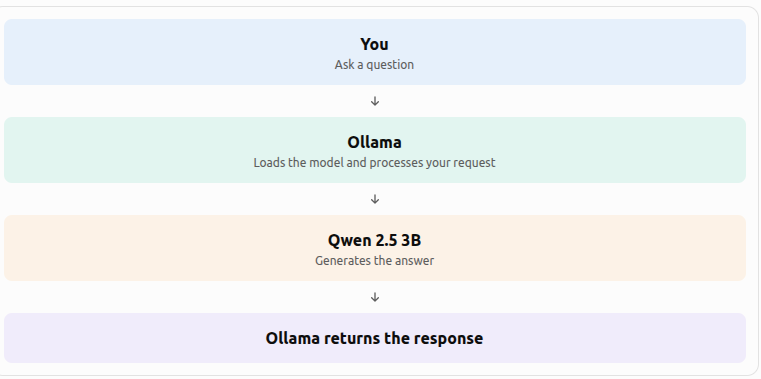

Why do we use Ollama?
- Local execution: Run models on your own computer.
- Privacy: Your prompts can stay on your machine rather than being sent to a cloud AI provider.
- No API key: You don't need a paid API key to run a downloaded model.
- Python integration: Connect local models to Python applications.
- Offline usage: Once the model is downloaded, you can run it without an internet connection.


# Ollama command: 
ollama show qwen2.5:3b
Displays information such as:
- Model architecture
- Parameters
- Quantization
- Model configuration

ollama ps
Displays models currently loaded and running.

Delete a model:
ollama rm qwen2.5:3b
Removes the downloaded model from your computer.
Be careful: this deletes the local model files.



# Understanding LLM Models in Ollama

What is an LLM model?
An LLM (Large Language Model) is a trained neural network that understands and generates text.

For example:
- Qwen 2.5
- Llama 3.2
- Gemma
- Mistral

# What are model parameters (3B, 7B, 8B)?

Parameters are the learned numerical values inside a neural network.
During training, the model learns these values from large amounts of data.
Think of parameters as the learned knowledge and patterns that help the model generate responses

More parameters can provide greater capacity to learn complex patterns.

Larger models usually require more RAM.

Larger models can be slower on CPU.

Smaller models are generally easier to run locally

# What is quantization?
Quantization is the process of reducing the precision of model weights to reduce memory requirements.

- A model stores billions of numerical values called weights.
- Normally, these values might use 16 bits (FP16) per parameter.
- Quantization converts them into lower-bit representations, such as 8-bit or 4-bit

1 byte = 8 bit

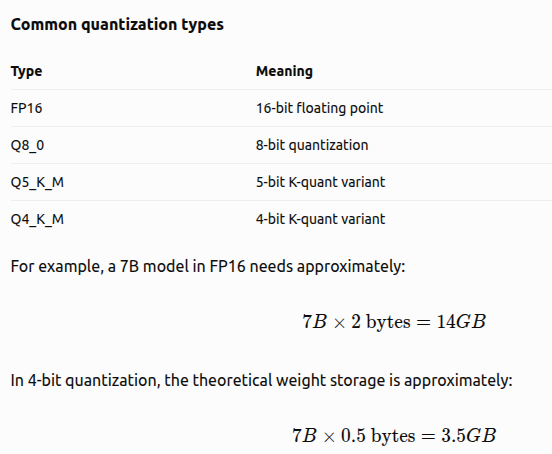


# What is a context window?
The context window is the maximum amount of tokens a model can process in a single context.

Tokens include:
- Input prompt
- Conversation history
- System instructions
- Retrieved documents in RAG
- Generated response



# Working with Ollama
Prompting an LLM : 
A prompt is the instruction or question that you give to an LLM.
The model processes the prompt and generates a response.

What is a System Prompt?

- A system prompt defines how an LLM should behave.
- For example, suppose you want to create an AI tutor that always explains concepts simply.
- You can provide this system instruction

# What is Temperature?
Temperature controls the randomness of the model's generated responses.
It generally ranges from 0 to 2 in Ollama's sampling configuration

Low temperature (0.0–0.3):
More predictable and consistent responses.
Useful for factual answers and structured tasks

Medium temperature (0.4–0.8):
Balanced responses with some variation.
Useful for general conversations.

High temperature (0.9–2.0)
More varied and potentially creative responses.
Useful for brainstorming and creative writing.



# What is Streaming?
Normally, an LLM generates a response token by token.
There are two ways your application can receive the response.

Without streaming:
The user waits until the complete response is generated.

With streaming:
The user receives the response as it is generated.


# Advantage of Ollama:
- privacy and security
- controle and fine tuning
- flexibility and experimentation

In [6]:
# Ollama with Python : Generate a response

import ollama
response=ollama.generate(
    model='starcoder:1b',
    prompt='what is ollama ? in simple language'
)
print(response['response'])

KeyboardInterrupt: 

In [ ]:
# Chat with Ollama:
import ollama 
messages=[{
    'role': 'system',
    'content':'you are my personal ai assistant'
}]
while True:
    question=input('enter what you want and to end the chat type exit ')
    if question=='exit':
        print('thankyou for the conversation , bye ')
        break
    messages.append({
        'role':'user',
        'content':question
    })
    response=ollama.chat(
        model='qwen2.5-coder:0.5b',
        messages=messages
    )
    answer=response['message']['content']
    print('AI response:',answer)
    messages.append({
        'role':'assistant',
        'content':answer
    })

AI response: CNN stands for Convolutional Neural Network. It is a type of neural network that was introduced in the early 2000s by Google. The main difference between CNNs and other types of neural networks is that CNNs are designed to be more efficient at recognizing and processing complex patterns in large amounts of data. CNNs use convolutional layers that allow them to extract features from the input data, which can then be passed through fully connected layers to make predictions or classify the data. CNNs can be used for a variety of tasks such as image recognition, natural language processing, and speech recognition.


# Ollama REST API
API stands for Application Programming Interface.

It allows two software applications to communicate with each other.

For example, imagine:
- Python is your application.
- Ollama is running your local LLM.
- Python wants to ask Qwen a question.
- The API provides a way to send that question and receive an answer.

# What is a REST API?
REST stands for Representational State Transfer.

It's an architectural style for building APIs that communicate using HTTP.
You don't need to memorize its theory. For now, understand these four HTTP methods:
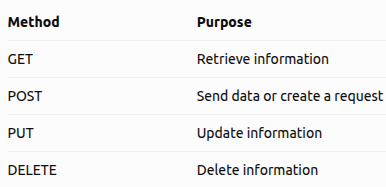

For Ollama, we'll mainly use GET and POST.

For example:
- GET /api/tags – Get downloaded models.
- POST /api/generate – Generate a response.
- POST /api/chat – Chat with a model.


Generate a response

Run this command:

curl -s http://localhost:11434/api/generate -d '{
  "model": "qwen2.5:3b",
  "prompt": "What is machine learning?",
  "stream": false
}' | jq -r '.response'

We set stream to false so that we receive one complete JSON response instead of multiple streamed JSON objects.
JSON (JavaScript Object Notation) is a lightweight, text-based format for storing and exchanging structured data. It is easy for humans to read and write, and easy for machines to parse and generate



JSON (JavaScript Object Notation) is a lightweight, text-based format for storing and exchanging structured data. It is easy for humans to read and write, and easy for machines to parse and generate

json is kind of data exchange format